In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import LabelEncoder

from sklearn.linear_model import LogisticRegression
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import LinearSVC

from sklearn.metrics import accuracy_score
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix
from sklearn.model_selection import cross_val_score

In [3]:
# Load Dataset

In [4]:
df = pd.read_excel("dataset.xlsx")

In [5]:
# EDA

In [6]:
df.head()

,title,rating,body
0,Horrible product,1,Very disappointed with the overall performance...
1,Camera quality is not like 48 megapixel,3,Camera quality is low
2,Overall,4,"Got the mobile on the launch date,Battery must..."
3,A big no from me,1,1. It doesn't work with 5.0GHz WiFi frequency....
4,Put your money somewhere else,1,"Not worth buying....faulty software, poor disp..."


In [7]:
df.tail()

,title,rating,body
1435,Excellent mobile,5,Excellent mobile
1436,Never expected from samsung,1,"All over mobile performance is very poor, neve..."
1437,Good value for money,5,Battery life is good but camera clarity could ...
1438,Unreal and whitish display,1,"It's a very bad product, highly dissatisfied....."
1439,Beast of the best.,5,The phone is a real beast the battery lasts ea...


In [8]:
df.shape

(1440, 3)

In [9]:
df.columns

Index(['title', 'rating', 'body'], dtype='str')

In [10]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1440 entries, 0 to 1439
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   title   1440 non-null   str  
 1   rating  1440 non-null   int64
 2   body    1440 non-null   str  
dtypes: int64(1), str(2)
memory usage: 508.5 KB


In [11]:
df.describe(include="all")

,title,rating,body
count,1440,1440.000000,1440
unique,1351,NaN,1440
top,Value for money,NaN,Very disappointed with the overall performance...
freq,16,NaN,1
mean,NaN,3.173611,NaN
std,NaN,1.584453,NaN
min,NaN,1.000000,NaN
25%,NaN,1.000000,NaN
50%,NaN,4.000000,NaN
75%,NaN,5.000000,NaN


In [12]:
df.isnull().sum()

title     0
rating    0
body      0
dtype: int64

In [13]:
df.dropna(inplace=True)

In [14]:
df.duplicated().sum()

np.int64(0)

In [15]:
df.duplicated().sum()

np.int64(0)

In [16]:
df["rating"].value_counts()

rating
5    419
1    386
4    310
3    199
2    126
Name: count, dtype: int64

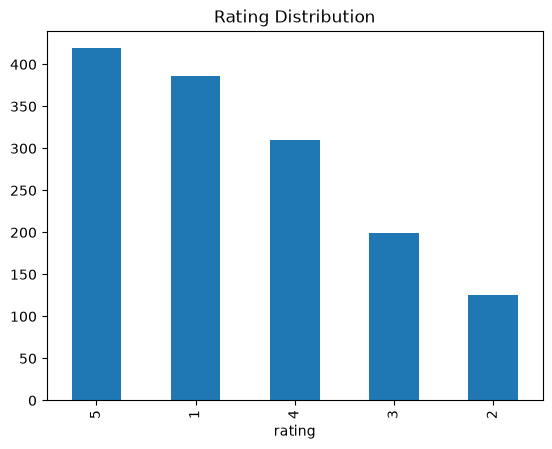

In [17]:
df["rating"].value_counts().plot(kind="bar")
plt.title("Rating Distribution")
plt.show()

In [18]:
df["Review_Length"]=df["body"].astype(str).apply(len)

In [19]:
df["Review_Length"].describe()

count    1440.000000
mean      302.109028
std       225.733052
min         4.000000
25%       170.000000
50%       246.000000
75%       359.000000
max      2490.000000
Name: Review_Length, dtype: float64

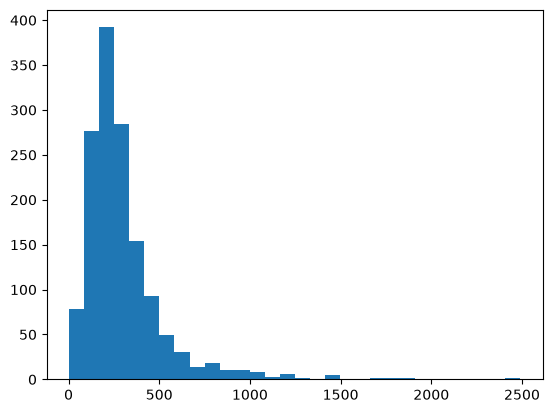

In [20]:
plt.hist(df["Review_Length"],bins=30)
plt.show()

In [21]:
def sentiment(x):

    if x>=4:
        return "Positive"

    elif x==3:
        return "Neutral"

    else:
        return "Negative"

df["Sentiment"]=df["rating"].apply(sentiment)

In [22]:
df["Sentiment"].value_counts()

Sentiment
Positive    729
Negative    512
Neutral     199
Name: count, dtype: int64

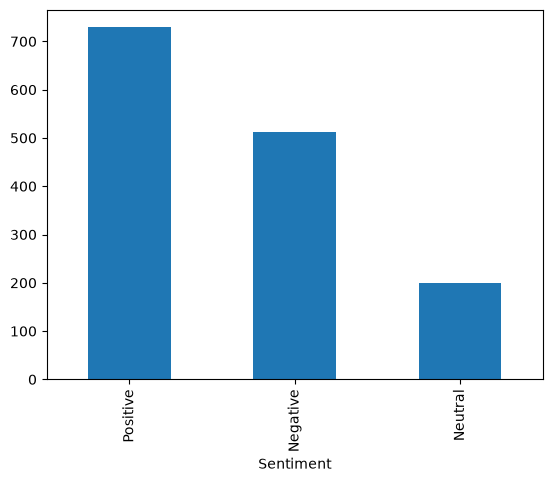

In [23]:
df["Sentiment"].value_counts().plot(kind="bar")
plt.show()

In [24]:
X=df["body"]

y=df["Sentiment"]

In [25]:
vectorizer=TfidfVectorizer(
stop_words="english",
max_features=5000
)

X=vectorizer.fit_transform(X)

In [26]:
X_train,X_test,y_train,y_test=train_test_split(
X,
y,
test_size=0.20,
random_state=42
)

In [27]:
# Model Building
#Logistic Regression

In [28]:
log_model=LogisticRegression(max_iter=1000)

log_model.fit(X_train,y_train)

log_pred=log_model.predict(X_test)

c:\Users\yashwanth\OneDrive\Desktop\nlp sentimental analysis\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(


In [29]:
# evaluation

In [30]:
print(accuracy_score(y_test,log_pred))

print(classification_report(y_test,log_pred))

print(confusion_matrix(y_test,log_pred))

0.7673611111111112
              precision    recall  f1-score   support

    Negative       0.87      0.82      0.84       111
     Neutral       1.00      0.05      0.09        44
    Positive       0.71      0.96      0.82       133

    accuracy                           0.77       288
   macro avg       0.86      0.61      0.58       288
weighted avg       0.81      0.77      0.71       288

[[ 91   0  20]
 [  9   2  33]
 [  5   0 128]]


In [31]:
# Random Forest

In [32]:
rf_model=RandomForestClassifier(
n_estimators=100,
random_state=42
)

rf_model.fit(X_train,y_train)

rf_pred=rf_model.predict(X_test)

In [33]:
# Evaluation

In [34]:
print(accuracy_score(y_test,rf_pred))

print(classification_report(y_test,rf_pred))

print(confusion_matrix(y_test,rf_pred))

0.7569444444444444
              precision    recall  f1-score   support

    Negative       0.88      0.79      0.83       111
     Neutral       0.00      0.00      0.00        44
    Positive       0.69      0.98      0.81       133

    accuracy                           0.76       288
   macro avg       0.52      0.59      0.55       288
weighted avg       0.66      0.76      0.70       288

[[ 88   0  23]
 [  9   0  35]
 [  3   0 130]]


c:\Users\yashwanth\OneDrive\Desktop\nlp sentimental analysis\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\Users\yashwanth\OneDrive\Desktop\nlp sentimental analysis\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\Users\yashwanth\OneDrive\Desktop\nlp sentimental analysis\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control th

In [35]:
# SVM

In [36]:
svm_model=LinearSVC()

svm_model.fit(X_train,y_train)

svm_pred=svm_model.predict(X_test)

In [37]:
print(accuracy_score(y_test,svm_pred))

print(classification_report(y_test,svm_pred))

print(confusion_matrix(y_test,svm_pred))

0.7743055555555556
              precision    recall  f1-score   support

    Negative       0.87      0.80      0.84       111
     Neutral       0.69      0.25      0.37        44
    Positive       0.72      0.92      0.81       133

    accuracy                           0.77       288
   macro avg       0.76      0.66      0.67       288
weighted avg       0.78      0.77      0.75       288

[[ 89   4  18]
 [  4  11  29]
 [  9   1 123]]


In [38]:
# Linear Regression

In [39]:
encoder=LabelEncoder()

y_train_lr=encoder.fit_transform(y_train)

y_test_lr=encoder.transform(y_test)

linear_model=LinearRegression()

linear_model.fit(X_train,y_train_lr)

linear_pred=linear_model.predict(X_test)

linear_pred=np.round(linear_pred)

linear_pred=np.clip(linear_pred,0,2)

In [40]:
print(accuracy_score(y_test_lr,linear_pred))

0.5520833333333334


In [41]:
# Cross Validation

In [42]:
# Logistic Regression

In [43]:
score=cross_val_score(
LogisticRegression(max_iter=1000),
X,
y,
cv=5
)

print(score.mean())

c:\Users\yashwanth\OneDrive\Desktop\nlp sentimental analysis\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(
c:\Users\yashwanth\OneDrive\Desktop\nlp sentimental analysis\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(
c:\Users\yashwanth\OneDrive\Desktop\nlp sentimental analysis\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(
c:\Users\yashwanth\OneDrive\Desktop\nlp sentimental analysis\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(
c:\Users\yashwanth\OneDrive\Desktop\nlp sentimental analysis\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = opti

0.7659722222222222


In [44]:
# Random Forest

In [45]:
score=cross_val_score(
RandomForestClassifier(),
X,
y,
cv=5
)

print(score.mean())

0.742361111111111


In [46]:
# SVM

In [47]:
score=cross_val_score(
LinearSVC(),
X,
y,
cv=5
)

print(score.mean())

0.7569444444444444


In [48]:
# 8. Underfitting / Overfitting

In [49]:
print("Logistic")

print(log_model.score(X_train,y_train))

print(log_model.score(X_test,y_test))

Logistic
0.875
0.7673611111111112


In [50]:
print("Logistic")

print(log_model.score(X_train,y_train))

print(log_model.score(X_test,y_test))

Logistic
0.875
0.7673611111111112


In [51]:
print("SVM")

print(svm_model.score(X_train,y_train))

print(svm_model.score(X_test,y_test))

SVM
0.9956597222222222
0.7743055555555556


In [52]:
# Model Comparison

In [53]:
result=pd.DataFrame({

"Model":[
"Logistic Regression",
"Random Forest",
"SVM",
"Linear Regression"
],

"Accuracy":[

accuracy_score(y_test,log_pred),

accuracy_score(y_test,rf_pred),

accuracy_score(y_test,svm_pred),

accuracy_score(y_test_lr,linear_pred)

]

})

print(result)

                 Model  Accuracy
0  Logistic Regression  0.767361
1        Random Forest  0.756944
2                  SVM  0.774306
3    Linear Regression  0.552083


In [54]:
print(result.sort_values("Accuracy",ascending=False))

                 Model  Accuracy
2                  SVM  0.774306
0  Logistic Regression  0.767361
1        Random Forest  0.756944
3    Linear Regression  0.552083


In [55]:
best_model = result.iloc[0]

print("Best Model :", best_model["Model"])
print("Accuracy :", best_model["Accuracy"])

Best Model : Logistic Regression
Accuracy : 0.7673611111111112


In [ ]:
# Deployment: train and save the complete text-to-sentiment pipeline
from pathlib import Path
import joblib
from sklearn.pipeline import Pipeline

# Build deployment labels from the review ratings.
deployment_data = pd.read_excel("dataset.xlsx").dropna(subset=["rating", "body"]).copy()
deployment_data["Sentiment"] = np.select(
    [deployment_data["rating"] >= 4, deployment_data["rating"] == 3],
    ["Positive", "Neutral"],
    default="Negative",
)
deployment_text = deployment_data["body"].astype(str)
deployment_labels = deployment_data["Sentiment"]

deployment_model = Pipeline([
    ("tfidf", TfidfVectorizer(stop_words="english", max_features=5000)),
    ("classifier", LinearSVC()),
])
deployment_model.fit(deployment_text, deployment_labels)

artifact_path = Path("sentiment_analysis_model.pkl")
joblib.dump(deployment_model, artifact_path)
loaded_model = joblib.load(artifact_path)

sample_review = "The product works great and I am very happy with it."
print(f"Saved deployment model: {artifact_path.resolve()}")
print(f"Training reviews: {len(deployment_data)}")
print(f"Sample review: {sample_review}")
print(f"Predicted sentiment: {loaded_model.predict([sample_review])[0]}")

Saved deployment model: C:\Users\yashwanth\OneDrive\Desktop\nlp sentimental analysis\sentiment_analysis_model.pkl
Training reviews: 1440
Sample review: The product works great and I am very happy with it.
Predicted sentiment: Positive


: 

## Run the Sentiment Analysis App

The deployment cell above saves the trained pipeline as `sentiment_analysis_model.pkl`, which is loaded by `app.py`.

1. From the project folder, run `run_app.bat` or start the app with `streamlit run app.py`.
2. Open the local app at **http://127.0.0.1:8501** while the Streamlit process is running.
3. Enter a product review and select **Analyze Sentiment** to get a prediction.

The deployment test produced:

```text
Training reviews: 1440
Sample review: The product works great and I am very happy with it.
Predicted sentiment: Positive
```

`http://127.0.0.1:8501` is a local development URL, accessible from this computer only. Public deployment requires hosting the app; the hosting provider will supply its public URL.